This notebook is used to test the conversion of <span style="font-variant:small-caps;">Nfa</span>s into <span style="font-variant:small-caps;">Dfa</span>s.

In [1]:
#use "../lib/nb.ml";;
run_notebook "01-NFA-2-DFA.ipynb"

- : unit = ()
Findlib has been successfully loaded. Additional directives:
  #require "package";;      to load a package
  #list;;                   to list the available packages
  #camlp4o;;                to load camlp4 (standard syntax)
  #camlp4r;;                to load camlp4 (revised syntax)
  #predicates "p,q,...";;   to set these predicates
  Topfind.reset();;         to force that packages will be reloaded
  #thread;;                 to enable threads

- : unit = ()
- : unit = ()
val lib_dir : string = "../lib"
val loaded_libs : (string, unit) Hashtbl.t = <abstr>
val load_lib : string -> unit = <fun>


- : unit = ()


In order to represent the finite state machines graphically, we use the notebook `FSM-2-Dot.ipynb`.  This
notebook uses the module `Graphviz` from the file `../lib/graphviz.ml`, which needs the program `dot` of the
*Graphviz* package.

In [2]:
run_notebook "FSM-2-Dot.ipynb"

- : unit = ()


In [3]:
let states = FSet.of_list (List.init 8 (fun i -> "q" ^ string_of_int i))

val states : string FSet.t = {"q0", "q1", "q2", "q3", "q4", "q5", "q6", "q7"}


In [4]:
let sigma = FSet.of_list [ 'a'; 'b' ]

val sigma : char FSet.t = {'a', 'b'}


In [5]:
let delta : string trans_rel = Dict.of_list [
    (("q0", Eps),     FSet.of_list [ "q1"; "q2" ]);
    (("q1", Sym 'b'), FSet.of_list [ "q3" ]);
    (("q2", Sym 'a'), FSet.of_list [ "q4" ]);
    (("q3", Sym 'a'), FSet.of_list [ "q5" ]);
    (("q4", Sym 'b'), FSet.of_list [ "q6" ]);
    (("q5", Eps),     FSet.of_list [ "q7" ]);
    (("q6", Eps),     FSet.of_list [ "q7" ]);
    (("q7", Eps),     FSet.of_list [ "q0" ]);
  ]

val delta : string trans_rel =
  {("q0", Eps) ↦ {"q1", "q2"}, ("q1", Sym 'b') ↦ {"q3"},
   ("q2", Sym 'a') ↦ {"q4"}, ("q3", Sym 'a') ↦ {"q5"},
   ("q4", Sym 'b') ↦ {"q6"}, ("q5", Eps) ↦ {"q7"}, ("q6", Eps) ↦ {"q7"},
   ("q7", Eps) ↦ {"q0"}}


The <span style="font-variant:small-caps;">Nfa</span> defined below is taken from the lecture notes.  The type
annotation `string nfa` tells the compiler that this record is an <span style="font-variant:small-caps;">Nfa</span>
whose states are strings.

In [6]:
let nfa44 : string nfa = { states; sigma; delta; start = "q0"; accepting = FSet.of_list [ "q7" ] }

val nfa44 : string nfa =
  {states = {"q0", "q1", "q2", "q3", "q4", "q5", "q6", "q7"};
   sigma = {'a', 'b'};
   delta =
    {("q0", Eps) ↦ {"q1", "q2"}, ("q1", Sym 'b') ↦ {"q3"},
     ("q2", Sym 'a') ↦ {"q4"}, ("q3", Sym 'a') ↦ {"q5"},
     ("q4", Sym 'b') ↦ {"q6"}, ("q5", Eps) ↦ {"q7"}, ("q6", Eps) ↦ {"q7"},
     ("q7", Eps) ↦ {"q0"}};
   start = "q0"; accepting = {"q7"}}


The function `nfa2dot` can be used to render this finite state machine.  Since the states are strings, the
function `show` that converts states into strings is the identity function `Fun.id`.

In [7]:
let d = nfa2dot ~show:Fun.id nfa44

val d : Graphviz.t = <abstr>


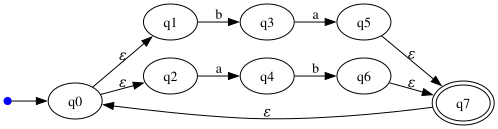

- : unit = ()


In [8]:
Graphviz.display d

This recognizes the same language as the language described by
$$ (a \cdot b + b \cdot a) \cdot (a \cdot b + b \cdot a)^* $$
Let us convert it into a <span style="font-variant:small-caps;">Dfa</span>: 

In [9]:
let dfa44 = nfa2dfa nfa44

val dfa44 : string FSet.t dfa =
  {states =
    {{}, {"q0", "q1", "q2"}, {"q0", "q1", "q2", "q5", "q7"},
     {"q0", "q1", "q2", "q6", "q7"}, {"q3"}, {"q4"}};
   sigma = {'a', 'b'};
   delta =
    {({}, 'a') ↦ {}, ({}, 'b') ↦ {}, ({"q0", "q1", "q2"}, 'a') ↦ {"q4"},
     ({"q0", "q1", "q2"}, 'b') ↦ {"q3"},
     ({"q0", "q1", "q2", "q5", "q7"}, 'a') ↦ {"q4"},
     ({"q0", "q1", "q2", "q5", "q7"}, 'b') ↦ {"q3"},
     ({"q0", "q1", "q2", "q6", "q7"}, 'a') ↦ {"q4"},
     ({"q0", "q1", "q2", "q6", "q7"}, 'b') ↦ {"q3"},
     ({"q3"}, 'a') ↦ {"q0", "q1", "q2", "q5", "q7"}, ({"q3"}, 'b') ↦ {},
     ({"q4"}, 'a') ↦ {}, ({"q4"}, 'b') ↦ {"q0", "q1", "q2", "q6", "q7"}};
   start = {"q0", "q1", "q2"};
   accepting =
    {{"q0", "q1", "q2", "q5", "q7"}, {"q0", "q1", "q2", "q6", "q7"}}}


The function `dfa2dot`can be used to render this finite state machine.

val dot : Graphviz.t = <abstr>
val states2Names : (string FSet.t, string) Dict.t =
  {{} ↦ "S0", {"q0", "q1", "q2"} ↦ "S1",
   {"q0", "q1", "q2", "q5", "q7"} ↦ "S2",
   {"q0", "q1", "q2", "q6", "q7"} ↦ "S3", {"q3"} ↦ "S4", {"q4"} ↦ "S5"}


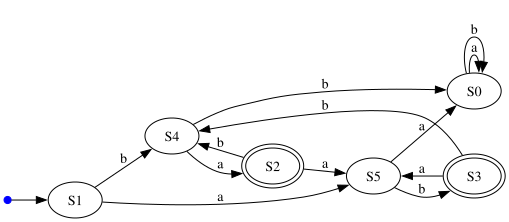

- : unit = ()


In [10]:
let dot, states2Names = dfa2dot dfa44
;;
Graphviz.display dot

In order to inspect the states of this <span style="font-variant:small-caps;">Dfa</span> we print the dictionary  `states2Names`.

In [11]:
states2Names

- : (string FSet.t, string) Dict.t =
{{} ↦ "S0", {"q0", "q1", "q2"} ↦ "S1", {"q0", "q1", "q2", "q5", "q7"} ↦ "S2",
 {"q0", "q1", "q2", "q6", "q7"} ↦ "S3", {"q3"} ↦ "S4", {"q4"} ↦ "S5"}


We can also print the <span style="font-variant:small-caps;">Dfa</span>.

In [12]:
dfa44

- : string FSet.t dfa =
{states =
  {{}, {"q0", "q1", "q2"}, {"q0", "q1", "q2", "q5", "q7"},
   {"q0", "q1", "q2", "q6", "q7"}, {"q3"}, {"q4"}};
 sigma = {'a', 'b'};
 delta =
  {({}, 'a') ↦ {}, ({}, 'b') ↦ {}, ({"q0", "q1", "q2"}, 'a') ↦ {"q4"},
   ({"q0", "q1", "q2"}, 'b') ↦ {"q3"},
   ({"q0", "q1", "q2", "q5", "q7"}, 'a') ↦ {"q4"},
   ({"q0", "q1", "q2", "q5", "q7"}, 'b') ↦ {"q3"},
   ({"q0", "q1", "q2", "q6", "q7"}, 'a') ↦ {"q4"},
   ({"q0", "q1", "q2", "q6", "q7"}, 'b') ↦ {"q3"},
   ({"q3"}, 'a') ↦ {"q0", "q1", "q2", "q5", "q7"}, ({"q3"}, 'b') ↦ {},
   ({"q4"}, 'a') ↦ {}, ({"q4"}, 'b') ↦ {"q0", "q1", "q2", "q6", "q7"}};
 start = {"q0", "q1", "q2"};
 accepting = {{"q0", "q1", "q2", "q5", "q7"}, {"q0", "q1", "q2", "q6", "q7"}}}
